In [51]:
import pandas as pd
import numpy as np

from urllib.parse import urlparse, parse_qs
from collections import Counter

import re
import math
import ipaddress

In [52]:
df = pd.read_csv(
    "../data/raw/urlset.csv",
    encoding="latin1",
    on_bad_lines="skip"
)

print(df.shape)

(95913, 14)


In [53]:
df = df.dropna(subset=["label"]).copy()

print(df.shape)
print(df["label"].value_counts())

(95913, 14)
label
0.0    48009
1.0    47904
Name: count, dtype: int64


In [54]:
def normalize_url(url):
    if not url.startswith(("http://", "https://")):
        return "http://" + url
    return url


df["normalized_url"] = df["domain"].apply(normalize_url)

In [55]:
df[["domain", "normalized_url"]].head()

,domain,normalized_url
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,http://nobell.it/70ffb52d079109dca5664cce6f317...
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,http://www.dghjdgf.com/paypal.co.uk/cycgi-bin/...
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,http://serviciosbys.com/paypal.cgi.bin.get-int...
3,mail.printakid.com/www.online.americanexpress....,http://mail.printakid.com/www.online.americane...
4,thewhiskeydregs.com/wp-content/themes/widescre...,http://thewhiskeydregs.com/wp-content/themes/w...


In [56]:
suspicious_words = [
    "login",
    "verify",
    "verification",
    "account",
    "secure",
    "update",
    "confirm",
    "signin",
    "password",
    "credential"
]

def extract_features(url):
    parsed = urlparse(url)
    hostname = parsed.hostname if parsed.hostname else ""
    path = parsed.path
    query = parsed.query
    
    # Basic URL features
    
    url_length = len(url)
    hostname_length = len(hostname)
    path_length = len(path)
    query_length = len(query)
    
    path_parts = [x for x in path.split('/') if x]
    path_depth = len(path_parts)
    
    query_params = parse_qs(query)
    unique_query_parameters = len(query_params)
    
    # Character features
    
    num_digits = sum(c.isdigit() for c in url)
    num_letters = sum(c.isalpha() for c in url)
    num_dots = url.count(".")
    num_hyphens = url.count("-")
    num_underscores = url.count("_")
    num_at = url.count("@")
    num_percent = url.count("%")
    num_question = url.count("?")
    num_ampersand = url.count("&")
    num_equal = url.count("=")
    
    digit_ratio = (
        num_digits / url_length
        if url_length else 0
    )

    letter_ratio = (
        num_letters / url_length
        if url_length else 0
    )

    special_chars = sum(
        not c.isalnum()
        for c in url
    )

    special_chars_ratio = (
        special_chars / url_length
        if url_length else 0
    )
    
      # IP address
      
    try:
        ipaddress.ip_address(hostname)
        is_ip = 1
    except ValueError:
        is_ip = 0
        
    # Hostname features
    
    hostname_parts = hostname.split('.') if hostname else []
    
    hostname_digit_count = sum(c.isdigit() for c in hostname)
    
    hostname_digit_ratio = (
        hostname_digit_count / hostname_length
        if hostname_length else 0
    )
    
    hostname_hyphens = hostname.count("-")

    hostname_part_count = len(hostname_parts)
    
    num_subdomain_like_parts = max(
        hostname_part_count - 2,
        0
    )

    longest_hostname_part = max(
        [len(part) for part in hostname_parts],
        default=0
    )
    
    # Path features
    
    path_digits = sum(
        c.isdigit() for c in path
    )

    path_special_chars = sum(
        not c.isalnum() and c != "/"
        for c in path
    )
    
    # Query features
    
    query_digits = sum(
        c.isdigit() for c in query
    )

    query_special_chars = sum(
        not c.isalnum()
        for c in query
    )
    
    
    # Suspicious words
    
    url_lower = url.lower()
    suspicious_word_count = sum(
        word in url_lower
        for word in suspicious_words
    )

    has_suspicious_word = (
        1 if suspicious_word_count > 0 else 0
    )
    
    # URL entropy
    
    entropy = 0
    if url_length > 0:
        counter = Counter(url)
        for count in counter.values():
            probability = count / url_length
            entropy -= (
                probability *
                math.log2(probability)
            )
    
     # Path entropy
     
    path_entropy = 0
    if path_length > 0:
        path_counter = Counter(path)
        for count in path_counter.values():
            probability = count / path_length
            path_entropy -= (
                probability *
                math.log2(probability)
            )
            
                # URL encoding
                
    encoded_parts = re.findall(
        r'%[0-9a-fA-F]{2}',
        url
    )

    encoded_character_count = len(encoded_parts)
    
    encoded_ratio = (
        encoded_character_count / url_length
        if url_length else 0
    )

    has_encoding = (
        1 if encoded_character_count > 0 else 0
    )
    
    # Other structural features
    
    has_at_symbol = 1 if "@" in url else 0

    double_slash_in_path = (
        1 if "//" in path else 0
    )

    fragment = parsed.fragment
    fragment_length = len(fragment)
    has_fragment = (
        1 if fragment else 0
    )
    
    # Return all features
    
    return {
        "url_length": url_length,
        "hostname_length": hostname_length,
        "path_length": path_length,
        "query_length": query_length,
        "path_depth": path_depth,
        "unique_query_parameters": unique_query_parameters,
        "num_digits": num_digits,
        "num_letters": num_letters,
        "num_dots": num_dots,
        "num_hyphens": num_hyphens,
        "num_underscores": num_underscores,
        "num_at": num_at,
        "num_percent": num_percent,
        "num_question": num_question,
        "num_ampersand": num_ampersand,
        "num_equal": num_equal,
        "digit_ratio": digit_ratio,
        "letter_ratio": letter_ratio,
        "special_chars_ratio": special_chars_ratio,
        "is_ip": is_ip,
        "hostname_digit_count": hostname_digit_count,
        "hostname_digit_ratio": hostname_digit_ratio,
        "hostname_hyphens": hostname_hyphens,
        "hostname_part_count": hostname_part_count,
        "num_subdomain_like_parts": num_subdomain_like_parts,
        "longest_hostname_part": longest_hostname_part,
        "path_digits": path_digits,
        "path_special_chars": path_special_chars,
        "query_digits": query_digits,
        "query_special_chars": query_special_chars,
        "suspicious_word_count": suspicious_word_count,
        "has_suspicious_word": has_suspicious_word,
        "url_entropy": entropy,
        "path_entropy": path_entropy,
        "encoded_character_count": encoded_character_count,
        "encoded_ratio": encoded_ratio,
        "has_encoding": has_encoding,
        "has_at_symbol": has_at_symbol,
        "double_slash_in_path": double_slash_in_path,
        "fragment_length": fragment_length,
        "has_fragment": has_fragment
    }

In [57]:
features_df = (
    df["normalized_url"]
    .apply(extract_features)
    .apply(pd.Series)
)

In [58]:
features_df["label"] = df["label"].astype(int).values

In [59]:
print(features_df.shape)
features_df.head()

(95913, 42)


,url_length,hostname_length,path_length,query_length,path_depth,unique_query_parameters,num_digits,num_letters,num_dots,num_hyphens,...,url_entropy,path_entropy,encoded_character_count,encoded_ratio,has_encoding,has_at_symbol,double_slash_in_path,fragment_length,has_fragment,label
0,232.0,9.0,125.0,90.0,8.0,4.0,58.0,139.0,6.0,4.0,...,5.046608,4.760640,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
1,88.0,15.0,66.0,0.0,4.0,0.0,1.0,69.0,5.0,2.0,...,4.720685,4.630997,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
2,184.0,16.0,161.0,0.0,10.0,0.0,47.0,115.0,7.0,1.0,...,4.739902,4.656329,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
3,67.0,18.0,42.0,0.0,2.0,0.0,0.0,56.0,6.0,0.0,...,4.179853,4.014358,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
4,123.0,19.0,60.0,36.0,6.0,0.0,21.0,86.0,1.0,1.0,...,4.623373,3.808719,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1


In [60]:
df = features_df.copy()

In [61]:
x = df.drop(columns='label')
y = df['label']

In [62]:
df.isnull().sum()

url_length                  0
hostname_length             0
path_length                 0
query_length                0
path_depth                  0
unique_query_parameters     0
num_digits                  0
num_letters                 0
num_dots                    0
num_hyphens                 0
num_underscores             0
num_at                      0
num_percent                 0
num_question                0
num_ampersand               0
num_equal                   0
digit_ratio                 0
letter_ratio                0
special_chars_ratio         0
is_ip                       0
hostname_digit_count        0
hostname_digit_ratio        0
hostname_hyphens            0
hostname_part_count         0
num_subdomain_like_parts    0
longest_hostname_part       0
path_digits                 0
path_special_chars          0
query_digits                0
query_special_chars         0
suspicious_word_count       0
has_suspicious_word         0
url_entropy                 0
path_entro

In [63]:
print(df.shape)
print(x.shape)
print(y.shape)

(95913, 42)
(95913, 41)
(95913,)


In [64]:
missing = df.isnull().sum()
print(missing[missing>0])

Series([], dtype: int64)


In [65]:
duplicates = x.duplicated().sum()
print("Duplicate feature rows:", duplicates)

Duplicate feature rows: 8467


Ab check karte hain koi feature har URL ke liye same toh nahi:

In [66]:
constant = []

for col in x.columns:
    if x[col].nunique() <= 1:
        constant.append(col)
        
print("Constant features:", constant)

Constant features: ['is_ip']


In [67]:
print(y.value_counts(normalize=True))

label
0    0.500547
1    0.499453
Name: proportion, dtype: float64


In [68]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
url_length,95913.0,71.454745,64.934216,16.000000,37.000000,49.000000,78.000000,2182.000000
hostname_length,95913.0,22.348034,23.388893,3.000000,14.000000,17.000000,22.000000,248.000000
path_length,95913.0,25.835090,26.016889,0.000000,11.000000,19.000000,33.000000,2156.000000
query_length,95913.0,15.931219,48.806466,0.000000,0.000000,0.000000,0.000000,1111.000000
path_depth,95913.0,2.349181,1.755752,0.000000,1.000000,2.000000,3.000000,34.000000
unique_query_parameters,95913.0,0.329559,0.848991,0.000000,0.000000,0.000000,0.000000,15.000000
num_digits,95913.0,8.168111,19.403227,0.000000,0.000000,1.000000,5.000000,286.000000
num_letters,95913.0,51.577190,44.926906,6.000000,28.000000,38.000000,57.000000,2145.000000
num_dots,95913.0,3.268858,2.330271,0.000000,2.000000,3.000000,3.000000,37.000000
num_hyphens,95913.0,0.655521,1.517959,0.000000,0.000000,0.000000,1.000000,36.000000


In [69]:
corr = x.corr()

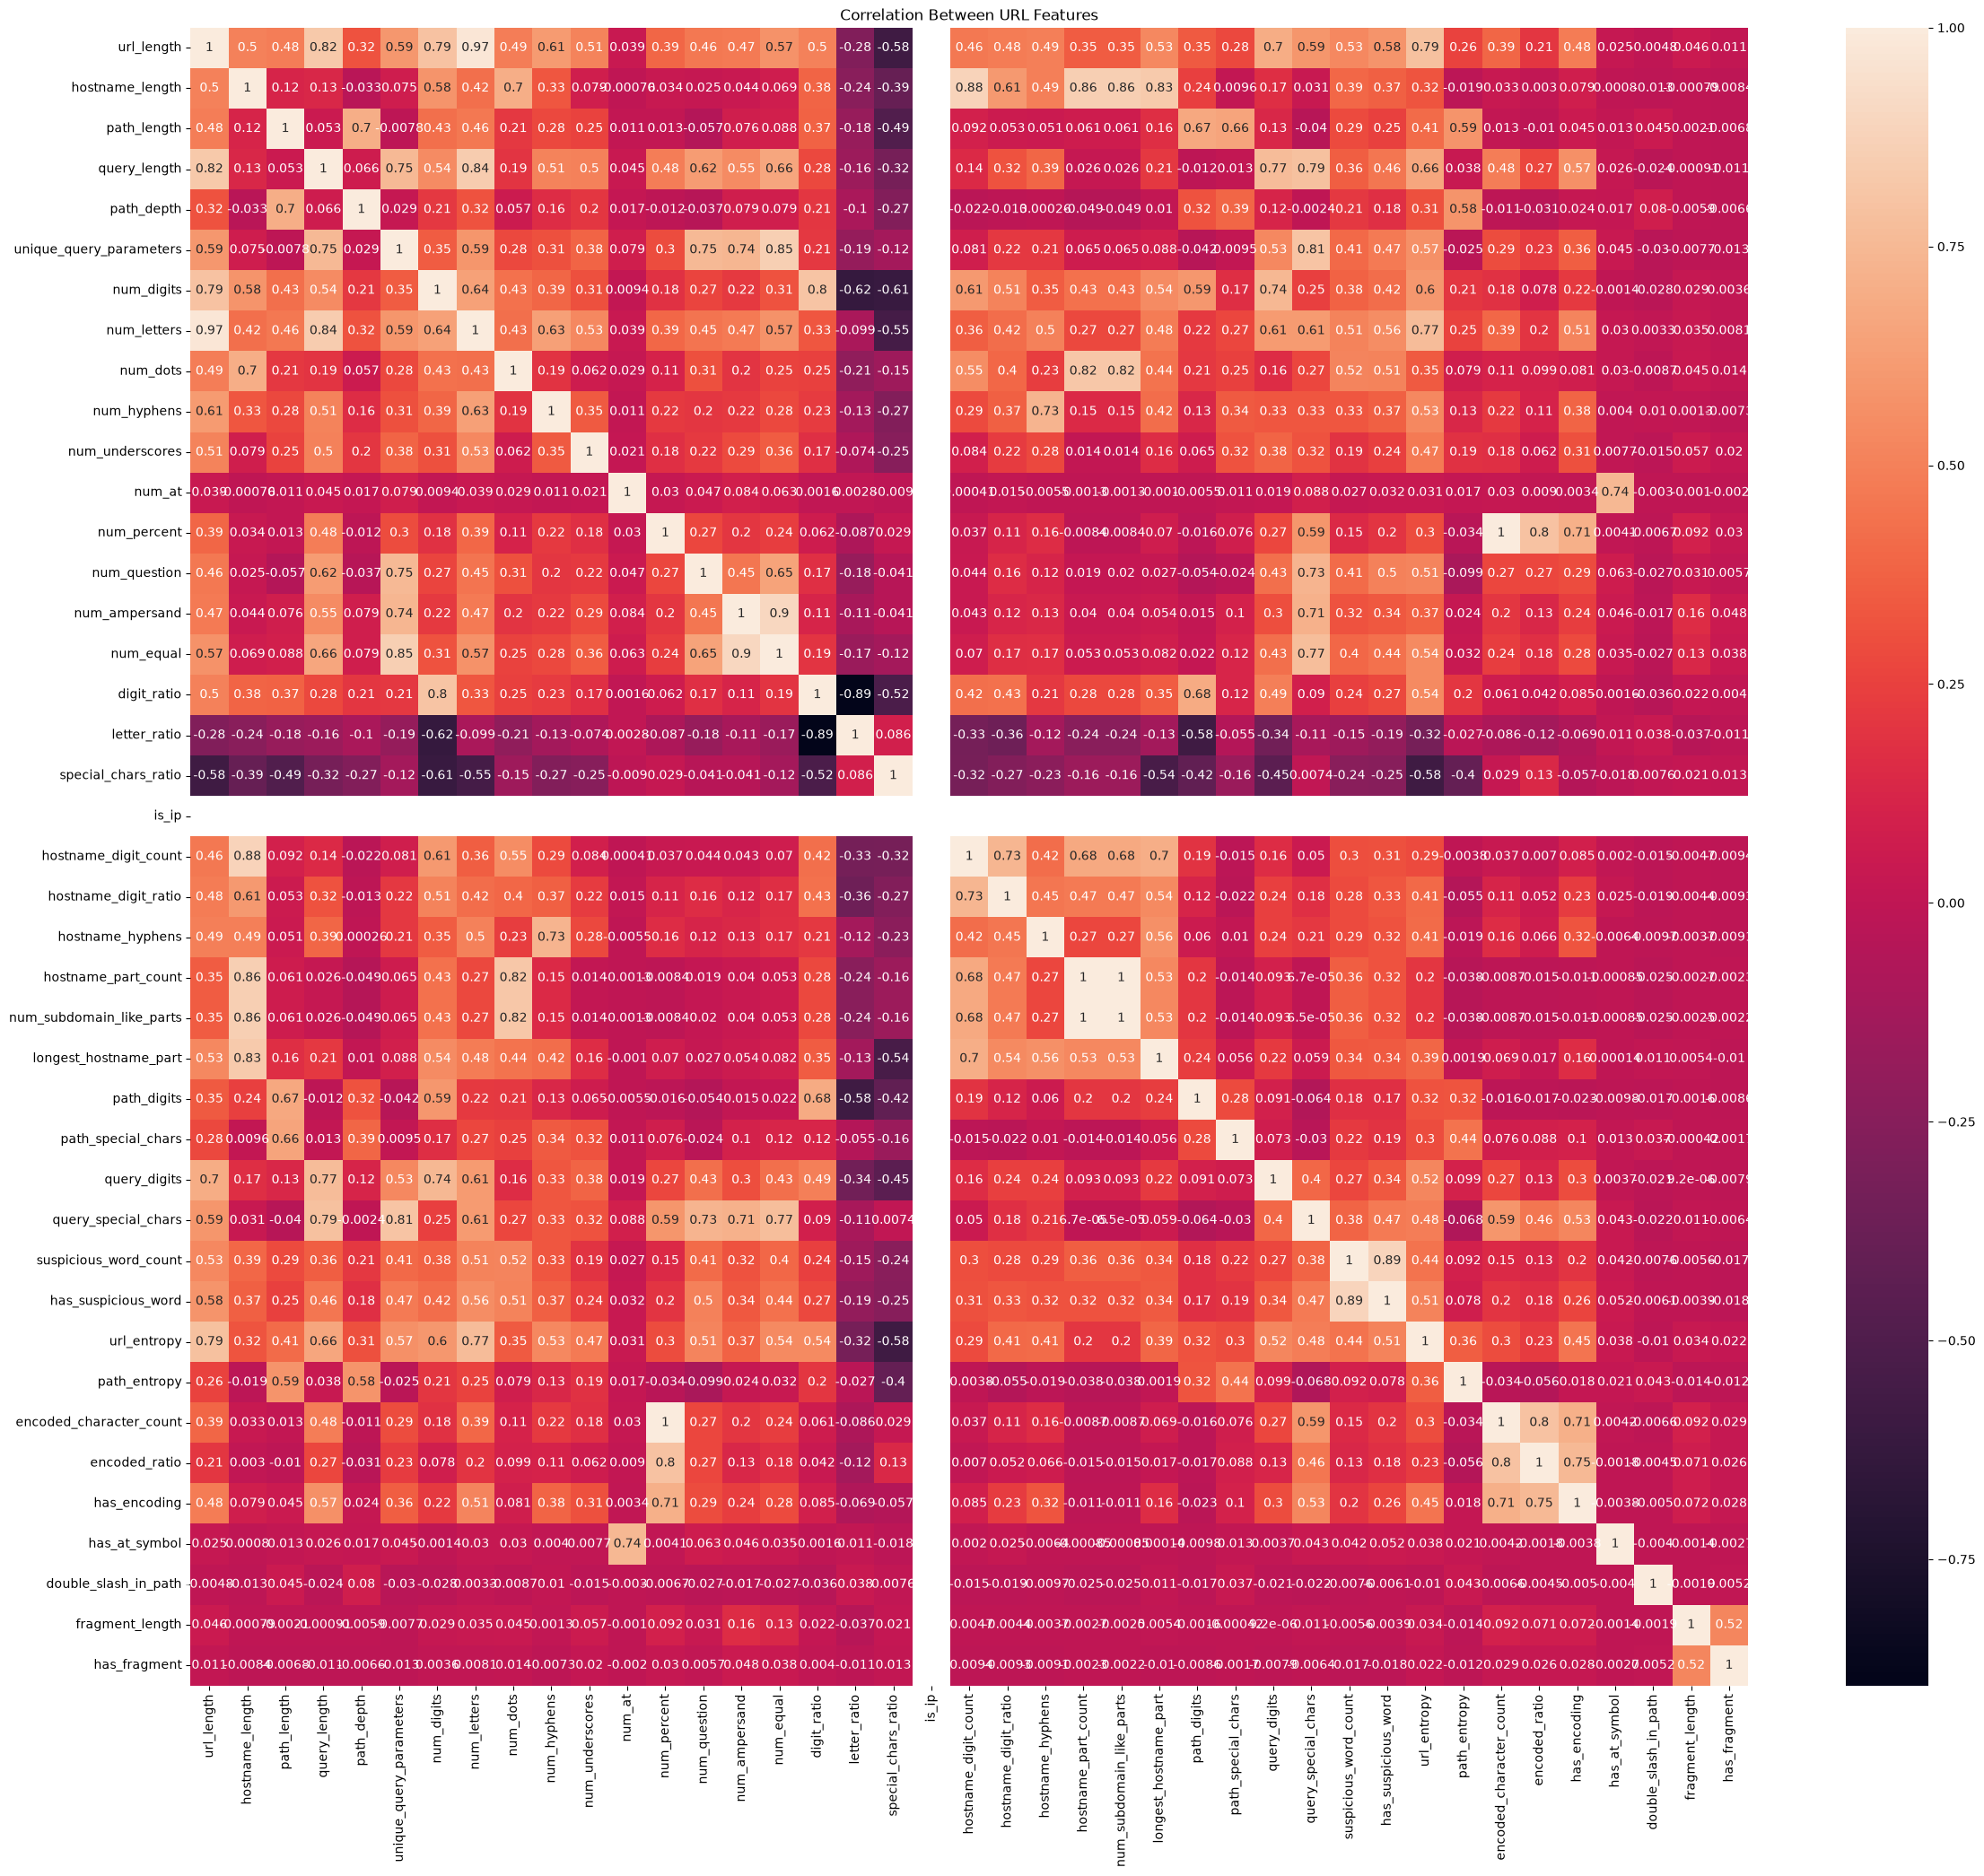

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(28, 24))

sns.heatmap(
    corr,
    annot=True
)

plt.title("Correlation Between URL Features")
plt.show()

In [71]:
pairs = []

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        value = corr.iloc[i, j]
        if abs(value) >= 0.80:
            pairs.append(
                (
                    corr.columns[i],
                    corr.columns[j],
                    value
                )
            )

pairs

[('url_length', 'query_length', np.float64(0.8224485767381883)),
 ('url_length', 'num_letters', np.float64(0.9721640070660393)),
 ('hostname_length', 'hostname_digit_count', np.float64(0.8778244029295486)),
 ('hostname_length', 'hostname_part_count', np.float64(0.8565555316916299)),
 ('hostname_length',
  'num_subdomain_like_parts',
  np.float64(0.8565627461912658)),
 ('hostname_length', 'longest_hostname_part', np.float64(0.8340254206523009)),
 ('query_length', 'num_letters', np.float64(0.8372389846788263)),
 ('unique_query_parameters', 'num_equal', np.float64(0.8548644182573004)),
 ('unique_query_parameters',
  'query_special_chars',
  np.float64(0.8058609933588723)),
 ('num_digits', 'digit_ratio', np.float64(0.8048932995445865)),
 ('num_dots', 'hostname_part_count', np.float64(0.8182153751756978)),
 ('num_dots', 'num_subdomain_like_parts', np.float64(0.8182019776816939)),
 ('num_percent', 'encoded_character_count', np.float64(0.999104700218269)),
 ('num_ampersand', 'num_equal', np.f

In [72]:
target_corr = df.corr()["label"].drop("label")

In [73]:
target_corr = target_corr.sort_values(
    ascending=False
)

print(target_corr)

has_suspicious_word         0.517131
suspicious_word_count       0.459158
url_entropy                 0.452291
url_length                  0.426296
num_letters                 0.401561
num_question                0.352396
num_digits                  0.342367
longest_hostname_part       0.341884
digit_ratio                 0.325133
unique_query_parameters     0.322387
num_equal                   0.318798
query_length                0.308447
query_special_chars         0.297175
num_dots                    0.276656
hostname_digit_ratio        0.274961
path_length                 0.258045
num_hyphens                 0.253270
query_digits                0.250077
hostname_length             0.242861
num_ampersand               0.228683
hostname_hyphens            0.224629
path_digits                 0.219815
path_depth                  0.204418
hostname_digit_count        0.196524
has_encoding                0.170862
path_special_chars          0.170217
num_underscores             0.152616
e

In [74]:
target_corr_abs = target_corr.abs().sort_values(
    ascending=False
)

print(target_corr_abs)

has_suspicious_word         0.517131
suspicious_word_count       0.459158
url_entropy                 0.452291
url_length                  0.426296
num_letters                 0.401561
num_question                0.352396
num_digits                  0.342367
longest_hostname_part       0.341884
digit_ratio                 0.325133
unique_query_parameters     0.322387
special_chars_ratio         0.321450
num_equal                   0.318798
query_length                0.308447
query_special_chars         0.297175
num_dots                    0.276656
hostname_digit_ratio        0.274961
path_length                 0.258045
num_hyphens                 0.253270
query_digits                0.250077
hostname_length             0.242861
num_ampersand               0.228683
hostname_hyphens            0.224629
path_digits                 0.219815
letter_ratio                0.211284
path_depth                  0.204418
hostname_digit_count        0.196524
has_encoding                0.170862
p

In [75]:
top = target_corr.abs().sort_values(
    ascending=False
).head(10)

print(top)

has_suspicious_word        0.517131
suspicious_word_count      0.459158
url_entropy                0.452291
url_length                 0.426296
num_letters                0.401561
num_question               0.352396
num_digits                 0.342367
longest_hostname_part      0.341884
digit_ratio                0.325133
unique_query_parameters    0.322387
Name: label, dtype: float64


In [76]:
print("Complete dataset shape:", df.shape)
print("Feature matrix shape:", x.shape)
print("Target shape:", y.shape)

Complete dataset shape: (95913, 42)
Feature matrix shape: (95913, 41)
Target shape: (95913,)


In [77]:
missing = df.isnull().sum()

print("Features with missing values:")
print(missing[missing > 0])

Features with missing values:
Series([], dtype: int64)


In [78]:
print(df.dtypes)

url_length                  float64
hostname_length             float64
path_length                 float64
query_length                float64
path_depth                  float64
unique_query_parameters     float64
num_digits                  float64
num_letters                 float64
num_dots                    float64
num_hyphens                 float64
num_underscores             float64
num_at                      float64
num_percent                 float64
num_question                float64
num_ampersand               float64
num_equal                   float64
digit_ratio                 float64
letter_ratio                float64
special_chars_ratio         float64
is_ip                       float64
hostname_digit_count        float64
hostname_digit_ratio        float64
hostname_hyphens            float64
hostname_part_count         float64
num_subdomain_like_parts    float64
longest_hostname_part       float64
path_digits                 float64
path_special_chars          

In [79]:
print("Target distribution:")
print(y.value_counts())

print("\nTarget percentage:")
print(y.value_counts(normalize=True)*100)

Target distribution:
label
0    48009
1    47904
Name: count, dtype: int64

Target percentage:
label
0    50.054737
1    49.945263
Name: proportion, dtype: float64


In [80]:
constant = []

for col in x.columns:
    if x[col].nunique() <= 1:
        constant.append(col)

print("Constant features:")
print(constant)

Constant features:
['is_ip']


# if
URL A → features = [10, 5, 2, ...] → label 1

URL B → features = [10, 5, 2, ...] → label 1

then ok

# else

URL A → same features → label 1

URL B → same features → label 0

not ok -> conflicting

Normally:
x.duplicated()
first occurrence ko duplicate nahi maanta.
keep=False se duplicate group ki saari rows milengi.

In [102]:
duplicate_mask = x.duplicated(keep=False)
duplicate_df = df[duplicate_mask].copy()
print("Rows belonging to duplicate feature groups:",

      len(duplicate_df))

Rows belonging to duplicate feature groups: 11379


In [103]:
# Identify all rows whose feature vectors are duplicated

duplicate_mask = x.duplicated(keep=False)
duplicate_df = df.loc[duplicate_mask].copy()
print("Total rows in duplicate groups:", len(duplicate_df))

Total rows in duplicate groups: 11379


In [82]:
duplicate_groups = (
    duplicate_df
    .groupby(list(x.columns))["label"]
    .agg(["count", "nunique"])
)

print("Number of duplicate feature groups:",
      len(duplicate_groups))

Number of duplicate feature groups: 2912


Find conflicting groups

In [83]:
conflicting_groups = duplicate_groups[
    duplicate_groups["nunique"] > 1
]

print("Conflicting feature groups:",
      len(conflicting_groups))

Conflicting feature groups: 61


Count rows involved in conflicts

let

Duplicate feature groups: 5000 

Conflicting feature groups: 100

Rows involved in conflicting groups: 250

Most duplicate feature representations are consistent, but 100 feature vectors map to both classes.

This means our feature representation is losing some information.

In [104]:
# Group identical feature vectors and count their unique labels

duplicate_groups = (
    duplicate_df
    .groupby(list(x.columns), dropna=False)["label"]
    .agg(["count", "nunique"])
)

conflicting_groups = duplicate_groups[
    duplicate_groups["nunique"] > 1
]

print("Total duplicate feature groups:", len(duplicate_groups))
print("Conflicting feature groups:", len(conflicting_groups))

Total duplicate feature groups: 2912
Conflicting feature groups: 61


In [119]:
# Show a few conflicting feature groups

conflicting_examples = duplicate_df.merge(
    conflicting_groups.reset_index()[list(x.columns)],
    on=list(x.columns),
    how="inner"
)

print("Rows in conflicting groups:", len(conflicting_examples))

conflicting_examples[["label"] + list(x.columns)].head(10)

Rows in conflicting groups: 148


,label,url_length,hostname_length,path_length,query_length,path_depth,unique_query_parameters,num_digits,num_letters,num_dots,...,has_suspicious_word,url_entropy,path_entropy,encoded_character_count,encoded_ratio,has_encoding,has_at_symbol,double_slash_in_path,fragment_length,has_fragment
0,1,30.0,16.0,7.0,0.0,1.0,0.0,0.0,23.0,2.0,...,0.0,3.748394,2.235926,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,30.0,16.0,7.0,0.0,1.0,0.0,0.0,23.0,2.0,...,0.0,3.923231,2.521641,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,31.0,15.0,9.0,0.0,1.0,0.0,0.0,24.0,2.0,...,0.0,3.897587,2.725481,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1,26.0,9.0,10.0,0.0,1.0,0.0,0.0,20.0,1.0,...,0.0,3.719295,2.721928,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1,29.0,18.0,4.0,0.0,1.0,0.0,0.0,22.0,2.0,...,0.0,3.797468,1.500000,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,1,28.0,16.0,5.0,0.0,1.0,0.0,0.0,21.0,2.0,...,0.0,3.807355,1.921928,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,1,25.0,11.0,7.0,0.0,1.0,0.0,0.0,18.0,2.0,...,0.0,3.813661,2.521641,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,1,32.0,18.0,7.0,0.0,1.0,0.0,0.0,25.0,2.0,...,0.0,3.866729,2.521641,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,1,26.0,12.0,7.0,0.0,1.0,0.0,0.0,19.0,2.0,...,0.0,3.796218,2.521641,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,1,30.0,15.0,8.0,0.0,1.0,0.0,0.0,23.0,3.0,...,0.0,4.006239,3.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [105]:
conflict_rows = (
    duplicate_df
    .groupby(list(x.columns))["label"]
    .filter(lambda s: s.nunique() > 1)
)

print("Rows involved in conflicting groups:",
      len(conflict_rows))

Rows involved in conflicting groups: 148


# CONSTANT FEATURES

In [106]:
feature_summary = pd.DataFrame({
    "unique_values": x.nunique(),
    "missing_values": x.isnull().sum(),
    "mean": x.mean(),
    "std": x.std()
})

feature_summary.sort_values(
    "unique_values"
).head(10)

,unique_values,missing_values,mean,std
is_ip,1,0,0.000000,0.000000
has_fragment,2,0,0.002898,0.053760
double_slash_in_path,2,0,0.006568,0.080780
has_at_symbol,2,0,0.002471,0.049648
has_encoding,2,0,0.035167,0.184203
has_suspicious_word,2,0,0.215174,0.410945
num_at,4,0,0.002794,0.075398
suspicious_word_count,7,0,0.278742,0.601428
num_question,12,0,0.234963,0.529145
hostname_hyphens,14,0,0.266856,0.897530


In [107]:
pairs = []
for i in range(len(corr.columns)):
    for j in range(i+1 , len(corr.columns)):
        value = corr.iloc[i,j]
        if abs(value) >= 0.80:
            pairs.append({
                "feature_1": corr.columns[i],
                "feature_2": corr.columns[j],
                "correlation": value
            })
            
high_corr = pd.DataFrame(pairs)
high_corr = high_corr.sort_values(
    "correlation",
    key=abs,
    ascending=False
)
            

In [108]:
high_corr

,feature_1,feature_2,correlation
15,hostname_part_count,num_subdomain_like_parts,0.999992
12,num_percent,encoded_character_count,0.999105
1,url_length,num_letters,0.972164
13,num_ampersand,num_equal,0.901833
14,digit_ratio,letter_ratio,-0.894441
16,suspicious_word_count,has_suspicious_word,0.885142
2,hostname_length,hostname_digit_count,0.877824
4,hostname_length,num_subdomain_like_parts,0.856563
3,hostname_length,hostname_part_count,0.856556
7,unique_query_parameters,num_equal,0.854864


In [109]:
tar_corr = df.corr()["label"].drop("label")

In [110]:
target_corr_abs = (target_corr.abs().sort_values(ascending=False)).head(15)

In [111]:
target_corr_abs

has_suspicious_word        0.517131
suspicious_word_count      0.459158
url_entropy                0.452291
url_length                 0.426296
num_letters                0.401561
num_question               0.352396
num_digits                 0.342367
longest_hostname_part      0.341884
digit_ratio                0.325133
unique_query_parameters    0.322387
special_chars_ratio        0.321450
num_equal                  0.318798
query_length               0.308447
query_special_chars        0.297175
num_dots                   0.276656
Name: label, dtype: float64

# IMPORTANT FEATURE VISUALIZATION

In [112]:
top_features = target_corr_abs.head(6).index.tolist()

In [113]:
print("Top features correlated with the target variable:")
print(top_features)

Top features correlated with the target variable:
['has_suspicious_word', 'suspicious_word_count', 'url_entropy', 'url_length', 'num_letters', 'num_question']


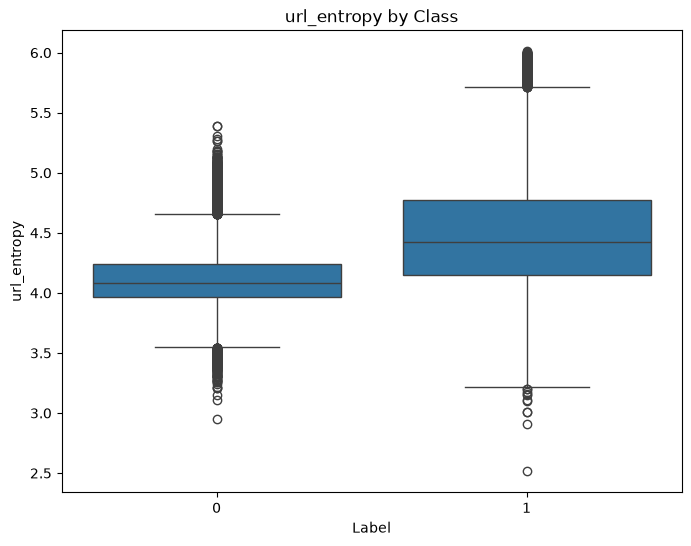

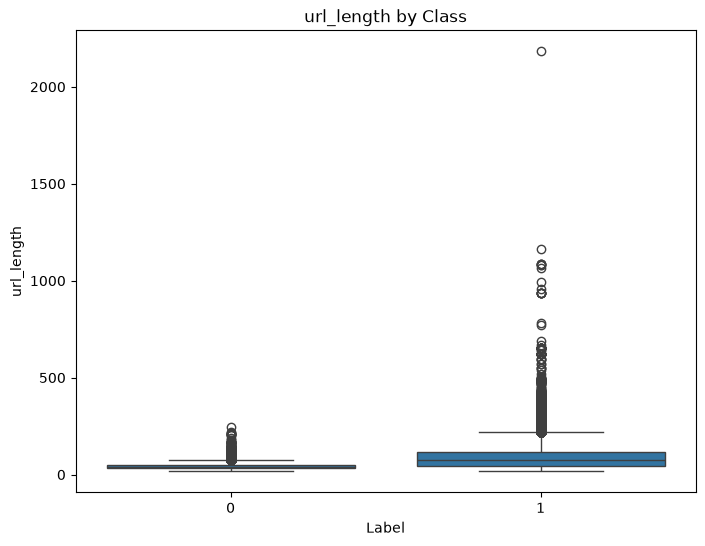

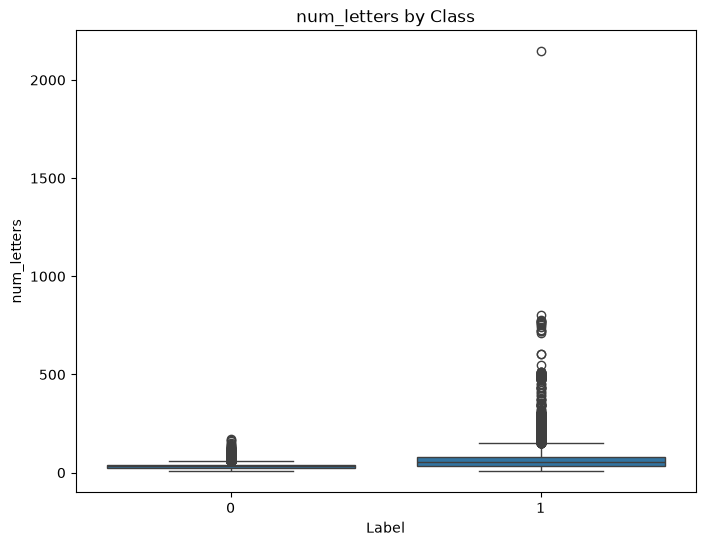

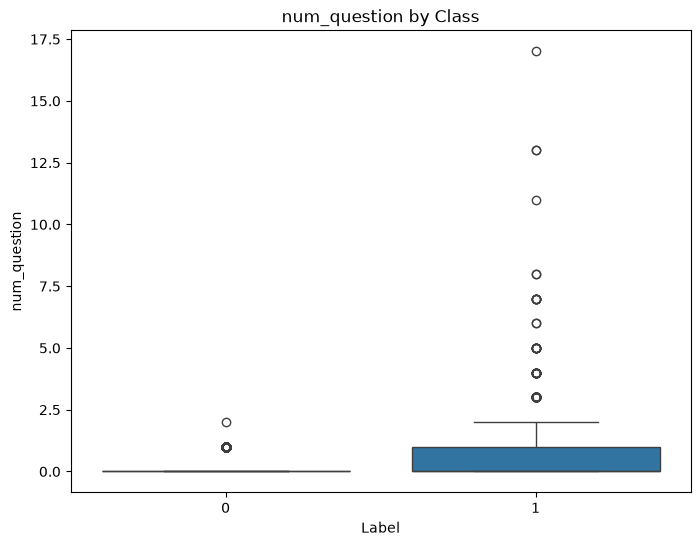

In [114]:
for feature in top_features:
    if x[feature].nunique() >= 10:
        plt.figure(figsize=(8, 6))
        sns.boxplot(
            x="label",y=feature,data=df
        )
        plt.title(f"{feature} by Class")
        plt.xlabel("Label")
        plt.ylabel(feature)
        plt.show()

In [115]:
binary_features = [
    col for col in x.columns
    if x[col].nunique() == 2
]

In [116]:
print(binary_features)

['has_suspicious_word', 'has_encoding', 'has_at_symbol', 'double_slash_in_path', 'has_fragment']


In [117]:
for feature in binary_features:
    table = pd.crosstab(
        df[feature],y,normalize="columns"
    )*100

In [120]:
print("\n", feature)
print(table)


 has_fragment
label                0          1
has_fragment                     
0.0           99.62507  99.795424
1.0            0.37493   0.204576


## Final Feature Dataset Preparation

In this section, we will:
1. Remove constant features.
2. Preserve the original URLs for later analysis.
3. Combine URLs, extracted features, and labels.
4. Save the final dataset for model training.

In [121]:
# Identify constant features
constant_features = [
    col for col in x.columns
    if x[col].nunique(dropna=False) <= 1
]

print("Constant features:", constant_features)

# Remove constant features
x_final = x.drop(columns=constant_features)

print("Original feature shape:", x.shape)
print("Final feature shape:", x_final.shape)

Constant features: ['is_ip']
Original feature shape: (95913, 41)
Final feature shape: (95913, 40)


In [122]:
# Reload original dataset
raw_df = pd.read_csv(
    "../data/raw/urlset.csv",
    encoding="latin1",
    on_bad_lines="skip"
)

# Keep rows with valid labels
raw_df = raw_df.dropna(subset=["label"]).copy()

# Normalize URLs
raw_df["normalized_url"] = raw_df["domain"].astype(str).apply(
    lambda url: url if url.startswith(("http://", "https://"))
    else "http://" + url
)

print("Original dataset shape:", raw_df.shape)
print("Feature dataset shape:", x_final.shape)

# Verify row alignment before combining
assert len(raw_df) == len(x_final) == len(y), (
    "Row counts do not match. Check preprocessing before proceeding."
)

assert raw_df["label"].astype(int).reset_index(drop=True).equals(
    y.astype(int).reset_index(drop=True)
), "Labels are not aligned. Check the row order before proceeding."

print("Row counts and label alignment verified.")

Original dataset shape: (95913, 15)
Feature dataset shape: (95913, 40)
Row counts and label alignment verified.


In [123]:
# Create final dataset
final_df = x_final.copy()

# Preserve original URLs as metadata
final_df.insert(
    0,
    "normalized_url",
    raw_df["normalized_url"].to_numpy()
)

# Add target column
final_df["label"] = y.astype(int).to_numpy()

print("Final dataset shape:", final_df.shape)
print("\nFirst five rows:")
display(final_df.head())

print("\nLabel distribution:")
print(final_df["label"].value_counts())

print("\nMissing values:", final_df.isnull().sum().sum())

Final dataset shape: (95913, 42)

First five rows:


,normalized_url,url_length,hostname_length,path_length,query_length,path_depth,unique_query_parameters,num_digits,num_letters,num_dots,...,url_entropy,path_entropy,encoded_character_count,encoded_ratio,has_encoding,has_at_symbol,double_slash_in_path,fragment_length,has_fragment,label
0,http://nobell.it/70ffb52d079109dca5664cce6f317...,232.0,9.0,125.0,90.0,8.0,4.0,58.0,139.0,6.0,...,5.046608,4.760640,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
1,http://www.dghjdgf.com/paypal.co.uk/cycgi-bin/...,88.0,15.0,66.0,0.0,4.0,0.0,1.0,69.0,5.0,...,4.720685,4.630997,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
2,http://serviciosbys.com/paypal.cgi.bin.get-int...,184.0,16.0,161.0,0.0,10.0,0.0,47.0,115.0,7.0,...,4.739902,4.656329,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
3,http://mail.printakid.com/www.online.americane...,67.0,18.0,42.0,0.0,2.0,0.0,0.0,56.0,6.0,...,4.179853,4.014358,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
4,http://thewhiskeydregs.com/wp-content/themes/w...,123.0,19.0,60.0,36.0,6.0,0.0,21.0,86.0,1.0,...,4.623373,3.808719,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1



Label distribution:
label
0    48009
1    47904
Name: count, dtype: int64

Missing values: 0


In [124]:
import os

# Create processed-data folder if it doesn't exist
os.makedirs("../data/processed", exist_ok=True)

# Save final dataset
output_path = "../data/processed/url_features.csv"

final_df.to_csv(output_path, index=False)

print("Final dataset saved successfully!")
print("File location:", output_path)
print("Rows:", final_df.shape[0])
print("Features:", len(x_final.columns))

Final dataset saved successfully!
File location: ../data/processed/url_features.csv
Rows: 95913
Features: 40
